# HMDB51 — Sequential Video Dataset Exploration

**Project:** Temporal & Multimodal Visual Intelligence  
**Notebook:** `01_dataset_exploration.ipynb`  
**Purpose:** Inspect the downloaded HMDB51 videos as ordered visual sequences before building frame embeddings or temporal models.

This notebook addresses the dataset-understanding stage of the assignment:

1. Load ordered video sequences.
2. Verify basic sequence integrity and frame ordering.
3. Generate dataset statistics.
4. Visualize sequences as temporal frame strips.
5. Identify examples where temporal information may help, where a single frame is ambiguous, and where temporal information may be unnecessary.

> **Current local dataset:** this notebook is designed for the partially downloaded HMDB51 mirror at `data/hmdb51/`. The current download contains approximately 950 AVI files across the classes that had downloaded when the transfer was interrupted. It does not assume that all 51 HMDB51 classes are present.

## Important experimental principles

- A video is an ordered sequence. Frame indices and timestamps must remain in chronological order.
- Keep the original video files unchanged.
- Do not split frames from the same video across train/validation/test sets. Splits must happen at the **video level**.
- Metadata files describe the repository's listed videos; a metadata row does not guarantee its video has downloaded.
- This notebook performs inspection only. It does not train a model or delete files.

## 0. Environment and imports

The notebook uses OpenCV for video decoding, pandas for metadata/statistics, and Matplotlib for temporal frame strips.

If needed, install dependencies in the project's Python 3.11 environment:
```bash
pip install opencv-python pandas numpy matplotlib tqdm seaborn
```

In [29]:
from __future__ import annotations

import json
import math
import random
import warnings
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["image.cmap"] = "gray"

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

OpenCV: 5.0.0
NumPy: 2.4.6
Pandas: 3.1.0


## 1. Locate the dataset

Expected layout:
```text
Tracking/
├── data/
│   └── hmdb51/
│       ├── videos/
│       │   ├── brush_hair/
│       │   ├── cartwheel/
│       │   └── ...
│       ├── metadata_train.csv
│       ├── metadata_test.csv
│       └── metadata_other.csv
└── notebooks/
    └── 01_dataset_exploration.ipynb
```

The path resolver checks common notebook and project-root locations. If it cannot find the data, set `DATA_ROOT` manually.

In [30]:
CANDIDATE_ROOTS = [
    Path("../data/hmdb51"),
    Path("data/hmdb51"),
    Path("../../data/hmdb51"),
    Path.cwd() / "data" / "hmdb51",
    Path.cwd().parent / "data" / "hmdb51",
]

DATA_ROOT = next(
    (p.resolve() for p in CANDIDATE_ROOTS if (p / "videos").exists()),
    None
)

if DATA_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/hmdb51. Set DATA_ROOT manually, e.g. "
        "DATA_ROOT = Path('/absolute/path/to/Tracking/data/hmdb51')"
    )

VIDEO_ROOT = DATA_ROOT / "videos"
print("Dataset root:", DATA_ROOT)
print("Video root:", VIDEO_ROOT)

Dataset root: /Users/vanshikaarora/Desktop/Tracking/data/hmdb51
Video root: /Users/vanshikaarora/Desktop/Tracking/data/hmdb51/videos


## 2. Load metadata and discover locally available videos

We load all three metadata CSVs when present. The `train` and `test` files are kept separate. The `other` file is inspected but is not automatically treated as a validation split because its role needs to be established from the dataset source.

The local file inventory is authoritative for what is actually available on disk.

In [31]:
metadata_frames = []

for split_name in ["train", "test", "other"]:
    csv_path = DATA_ROOT / f"metadata_{split_name}.csv"
    if csv_path.exists():
        frame = pd.read_csv(csv_path)
        frame["metadata_source_split"] = split_name
        metadata_frames.append(frame)
        print(f"{csv_path.name}: {len(frame):,} rows")
    else:
        print(f"Missing: {csv_path.name}")

if metadata_frames:
    metadata = pd.concat(metadata_frames, ignore_index=True)
else:
    metadata = pd.DataFrame(columns=["file_name", "label", "metadata_source_split"])

required_columns = {"file_name", "label"}
if not required_columns.issubset(metadata.columns):
    raise ValueError(f"Metadata must contain columns {required_columns}; found {metadata.columns.tolist()}")

metadata.head()

metadata_train.csv: 3,570 rows
metadata_test.csv: 1,530 rows
metadata_other.csv: 1,666 rows


,file_name,label,metadata_source_split
0,videos/brush_hair/April_09_brush_hair_u_nm_np1...,brush_hair,train
1,videos/brush_hair/April_09_brush_hair_u_nm_np1...,brush_hair,train
2,videos/brush_hair/April_09_brush_hair_u_nm_np1...,brush_hair,train
3,videos/brush_hair/Aussie_Brunette_Brushing_Hai...,brush_hair,train
4,videos/brush_hair/Aussie_Brunette_Brushing_Hai...,brush_hair,train


In [32]:
video_paths = sorted(VIDEO_ROOT.rglob("*.avi"))
inventory = pd.DataFrame({
    "video_path": video_paths,
    "relative_path": [p.relative_to(DATA_ROOT).as_posix() for p in video_paths],
    "label_from_folder": [p.parent.name for p in video_paths],
    "file_size_bytes": [p.stat().st_size for p in video_paths],
})

inventory["file_size_mb"] = inventory["file_size_bytes"] / (1024 ** 2)

print(f"AVI files found: {len(inventory):,}")
print(f"Total AVI storage: {inventory['file_size_bytes'].sum() / (1024**2):,.2f} MB")
print(f"Classes found: {inventory['label_from_folder'].nunique()}")
display(inventory.head())

AVI files found: 950
Total AVI storage: 325.05 MB
Classes found: 9


,video_path,relative_path,label_from_folder,file_size_bytes,file_size_mb
0,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,videos/brush_hair/April_09_brush_hair_u_nm_np1...,brush_hair,838656,0.799805
1,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,videos/brush_hair/April_09_brush_hair_u_nm_np1...,brush_hair,772608,0.736816
2,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,videos/brush_hair/April_09_brush_hair_u_nm_np1...,brush_hair,806912,0.769531
3,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,videos/brush_hair/Aussie_Brunette_Brushing_Hai...,brush_hair,865792,0.825684
4,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,videos/brush_hair/Aussie_Brunette_Brushing_Hai...,brush_hair,581120,0.554199


## 3. Verify metadata-to-file correspondence

The mirror metadata uses `file_name` and `label`. Depending on how the CSV was prepared, `file_name` may be a path relative to the repository root or may contain only a filename. We test several plausible path interpretations rather than assuming one.

We then report:
- metadata rows whose corresponding local video exists;
- metadata rows whose video is missing locally;
- downloaded files that do not match a metadata row;
- disagreements between the metadata label and the folder label.

A partial download is expected to produce missing local files. That is not, by itself, evidence of corrupt data.

In [33]:
def resolve_metadata_video(value: str) -> Path | None:
    value = str(value).replace("\\", "/").lstrip("./")
    candidates = [
        DATA_ROOT / value,
        VIDEO_ROOT / value,
        VIDEO_ROOT / Path(value).name,
    ]
    for candidate in candidates:
        if candidate.is_file() and candidate.suffix.lower() == ".avi":
            return candidate.resolve()
    return None

metadata_check = metadata.copy()
metadata_check["resolved_local_path"] = metadata_check["file_name"].map(resolve_metadata_video)
metadata_check["exists_locally"] = metadata_check["resolved_local_path"].notna()

print("Metadata rows:", len(metadata_check))
print("Rows with local video:", int(metadata_check["exists_locally"].sum()))
print("Rows without local video:", int((~metadata_check["exists_locally"]).sum()))

# Compare local inventory paths against metadata-resolved paths.
resolved_metadata_paths = set(
    p for p in metadata_check["resolved_local_path"].dropna().tolist()
)
inventory_paths = set(p.resolve() for p in inventory["video_path"].tolist())
unmatched_local = inventory_paths - resolved_metadata_paths

print("Downloaded videos not matched to metadata:", len(unmatched_local))

if not metadata_check.empty:
    display(
        metadata_check.groupby(
            ["metadata_source_split", "exists_locally"]
        ).size().unstack(fill_value=0)
    )

metadata_check.head()

Metadata rows: 6766
Rows with local video: 950
Rows without local video: 5816
Downloaded videos not matched to metadata: 0


exists_locally,False,True
metadata_source_split,,
other,1563,103
test,1281,249
train,2972,598


,file_name,label,metadata_source_split,resolved_local_path,exists_locally
0,videos/brush_hair/April_09_brush_hair_u_nm_np1...,brush_hair,train,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,True
1,videos/brush_hair/April_09_brush_hair_u_nm_np1...,brush_hair,train,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,True
2,videos/brush_hair/April_09_brush_hair_u_nm_np1...,brush_hair,train,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,True
3,videos/brush_hair/Aussie_Brunette_Brushing_Hai...,brush_hair,train,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,True
4,videos/brush_hair/Aussie_Brunette_Brushing_Hai...,brush_hair,train,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,True


In [34]:
# # Compare the class in metadata with the class folder for matched videos.
# matched = metadata_check[metadata_check["exists_locally"]].copy()
# if len(matched):
#     matched["folder_label"] = matched["resolved_local_path"].map(lambda p: Path(p).parent.name)
#     matched["label_matches_folder"] = matched["label"].astype(str) == matched["folder_label"].astype(str)

#     print("Metadata/folder label disagreements:",
#           int((~matched["label_matches_folder"]).sum()))
#     display(
#         matched.loc[~matched["label_matches_folder"],
#                     ["file_name", "label", "folder_label"]].head(20)
#     )
# else:
#     print("No metadata rows currently resolve to local video files.")
# CELL 6: FRAME EXTRACTION AND PERSISTENCE

PROCESSED_ROOT = DATA_ROOT.parent / "processed"
FRAMES_ROOT = PROCESSED_ROOT / "frames"

NUM_FRAMES = 8
IMAGE_QUALITY = 95

FRAMES_ROOT.mkdir(parents=True, exist_ok=True)


def extract_and_save_frames(
    video_path: Path,
    num_frames: int = NUM_FRAMES
):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        cap.release()
        return []

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS))

    if total_frames <= 0:
        cap.release()
        return []

    indices = np.linspace(
        0,
        total_frames - 1,
        min(num_frames, total_frames),
        dtype=int
    )

    indices = np.unique(indices)

    label = video_path.parent.name
    video_id = video_path.stem

    output_dir = FRAMES_ROOT / label / video_id
    output_dir.mkdir(parents=True, exist_ok=True)

    records = []

    for position, frame_idx in enumerate(indices):

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
        success, frame = cap.read()

        if not success:
            continue

        frame_name = f"frame_{position:02d}.jpg"
        frame_path = output_dir / frame_name

        cv2.imwrite(
            str(frame_path),
            frame,
            [cv2.IMWRITE_JPEG_QUALITY, IMAGE_QUALITY]
        )

        records.append({
            "video_id": video_id,
            "label": label,
            "frame_index": int(frame_idx),
            "frame_position": position,
            "timestamp_sec": (
                frame_idx / fps if fps > 0 else np.nan
            ),
            "frame_path": str(frame_path),
        })

    cap.release()

    records.sort(key=lambda x: x["frame_index"])

    return records


print("Frame extraction function ready.")
print("Output directory:", FRAMES_ROOT)

Frame extraction function ready.
Output directory: /Users/vanshikaarora/Desktop/Tracking/data/processed/frames


## 4. Class distribution and storage statistics

These statistics describe the **downloaded subset**, not the complete HMDB51 dataset. We report counts from the actual local AVI inventory, not from the full metadata alone.

,video_count,total_size_mb,mean_size_mb,median_size_mb
label_from_folder,,,,
clap,130,32.52,0.25,0.23
dive,127,34.08,0.27,0.25
climb_stairs,112,33.39,0.30,0.30
chew,109,32.27,0.30,0.28
climb,108,53.74,0.50,0.43
brush_hair,107,81.20,0.76,0.82
cartwheel,107,29.65,0.28,0.27
catch,102,17.45,0.17,0.16
draw_sword,48,10.76,0.22,0.22


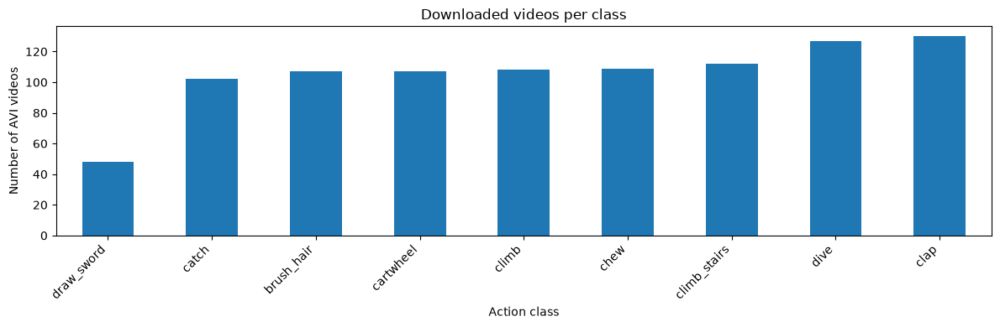

In [35]:
class_stats = (
    inventory.groupby("label_from_folder")
    .agg(
        video_count=("video_path", "count"),
        total_size_mb=("file_size_mb", "sum"),
        mean_size_mb=("file_size_mb", "mean"),
        median_size_mb=("file_size_mb", "median"),
    )
    .sort_values("video_count", ascending=False)
)

display(class_stats.round(2))

ax = class_stats["video_count"].sort_values().plot(
    kind="bar", figsize=(12, 4), title="Downloaded videos per class"
)
ax.set_xlabel("Action class")
ax.set_ylabel("Number of AVI videos")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 5. Video decoder and sequence-integrity inspection

For each video, OpenCV reads container metadata and attempts to decode frames. We collect:

- reported frame count;
- decoded frame count;
- FPS;
- width and height;
- estimated duration;
- whether decoding reached the reported frame count;
- whether frames could be read in increasing frame-index order.

**Frame-order verification:** OpenCV's sequential `read()` returns frames in decoder order. We record the monotonically increasing decode index. This confirms that our sampling code preserves the order returned by the decoder; it does not independently prove that the original recording has no editing or timestamp anomalies.

The full decode check can take a little time. `MAX_VIDEOS_TO_DECODE = None` means inspect all locally downloaded videos. For a quick smoke test, set it to a small integer such as 30.

In [36]:
# MAX_VIDEOS_TO_DECODE = None  # None = inspect every downloaded AVI

# paths_to_inspect = video_paths if MAX_VIDEOS_TO_DECODE is None else video_paths[:MAX_VIDEOS_TO_DECODE]

# def inspect_video(path: Path) -> dict:
#     cap = cv2.VideoCapture(str(path))
#     if not cap.isOpened():
#         return {
#             "video_path": str(path),
#             "label": path.parent.name,
#             "opened": False,
#             "reported_frames": 0,
#             "decoded_frames": 0,
#             "fps": np.nan,
#             "width": 0,
#             "height": 0,
#             "duration_sec": np.nan,
#             "decode_complete": False,
#             "decode_error": "VideoCapture could not open file",
#         }

#     reported = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
#     fps = float(cap.get(cv2.CAP_PROP_FPS))
#     width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
#     height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

#     decoded = 0
#     last_frame = None
#     while True:
#         ok, frame = cap.read()
#         if not ok:
#             break
#         decoded += 1
#         last_frame = frame

#     cap.release()

#     duration = (reported / fps) if fps > 0 and reported > 0 else np.nan
#     complete = reported > 0 and decoded == reported

#     return {
#         "video_path": str(path),
#         "label": path.parent.name,
#         "opened": True,
#         "reported_frames": reported,
#         "decoded_frames": decoded,
#         "fps": fps,
#         "width": width,
#         "height": height,
#         "duration_sec": duration,
#         "decode_complete": complete,
#         "decode_error": None if decoded > 0 else "No frames decoded",
#     }

# inspection_records = [
#     inspect_video(path) for path in tqdm(paths_to_inspect, desc="Decoding videos")
# ]
# video_stats = pd.DataFrame(inspection_records)

# print("Videos inspected:", len(video_stats))
# print("Videos opened:", int(video_stats["opened"].sum()))
# print("Videos with at least one decoded frame:", int((video_stats["decoded_frames"] > 0).sum()))
# print("Videos with reported/decoded frame-count match:",
#       int(video_stats["decode_complete"].sum()))

# display(video_stats.head())
# CELL 8: EXTRACT AND SAVE ALL VIDEO SEQUENCES

# CELL 8: VIDEO INSPECTION + FRAME EXTRACTION + METADATA SAVING

MAX_VIDEOS_TO_DECODE = None  # None = inspect all downloaded videos

paths_to_inspect = (
    video_paths
    if MAX_VIDEOS_TO_DECODE is None
    else video_paths[:MAX_VIDEOS_TO_DECODE]
)

# --------------------------------------------------
# 1. VIDEO INSPECTION
# --------------------------------------------------

def inspect_video(path: Path) -> dict:

    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        cap.release()

        return {
            "video_path": str(path),
            "label": path.parent.name,
            "opened": False,
            "reported_frames": 0,
            "decoded_frames": 0,
            "fps": np.nan,
            "width": 0,
            "height": 0,
            "duration_sec": np.nan,
            "decode_complete": False,
            "decode_error": "VideoCapture could not open file",
        }

    reported = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    decoded = 0

    while True:
        ok, frame = cap.read()

        if not ok:
            break

        decoded += 1

    cap.release()

    duration = (
        reported / fps
        if fps > 0 and reported > 0
        else np.nan
    )

    complete = reported > 0 and decoded == reported

    return {
        "video_path": str(path),
        "label": path.parent.name,
        "opened": True,
        "reported_frames": reported,
        "decoded_frames": decoded,
        "fps": fps,
        "width": width,
        "height": height,
        "duration_sec": duration,
        "decode_complete": complete,
        "decode_error": None if decoded > 0 else "No frames decoded",
    }


# --------------------------------------------------
# 2. INSPECT ALL VIDEOS
# --------------------------------------------------

inspection_records = []

for path in tqdm(paths_to_inspect, desc="Inspecting videos"):

    try:
        inspection_records.append(
            inspect_video(Path(path))
        )

    except Exception as e:

        inspection_records.append({
            "video_path": str(path),
            "label": Path(path).parent.name,
            "opened": False,
            "reported_frames": 0,
            "decoded_frames": 0,
            "fps": np.nan,
            "width": 0,
            "height": 0,
            "duration_sec": np.nan,
            "decode_complete": False,
            "decode_error": str(e),
        })


# IMPORTANT: Preserve this variable for later notebook cells.
video_stats = pd.DataFrame(inspection_records)

print("\nVIDEO INSPECTION SUMMARY")
print("-" * 60)

print("Videos inspected:", len(video_stats))
print("Videos opened:", int(video_stats["opened"].sum()))

print(
    "Videos with decoded frames:",
    int((video_stats["decoded_frames"] > 0).sum())
)

print(
    "Videos with reported/decoded frame-count match:",
    int(video_stats["decode_complete"].sum())
)

display(video_stats.head())


# --------------------------------------------------
# 3. SAVE VIDEO STATISTICS
# --------------------------------------------------

PROCESSED_ROOT.mkdir(parents=True, exist_ok=True)

video_stats.to_csv(
    PROCESSED_ROOT / "video_statistics.csv",
    index=False
)

print("Video statistics saved.")


# --------------------------------------------------
# 4. EXTRACT AND SAVE ORDERED FRAMES
# --------------------------------------------------

all_sequence_records = []

failed_videos = []

for video_path in tqdm(
    video_paths,
    desc="Extracting video frames"
):

    try:

        records = extract_and_save_frames(
            Path(video_path),
            num_frames=NUM_FRAMES
        )

        if not records:
            failed_videos.append(str(video_path))
            continue

        all_sequence_records.extend(records)

    except Exception as e:

        failed_videos.append(str(video_path))

        print(
            f"Error processing {video_path}: {e}"
        )


# --------------------------------------------------
# 5. SAVE FRAME-LEVEL SEQUENCE METADATA
# --------------------------------------------------

sequences_df = pd.DataFrame(all_sequence_records)

sequences_df.to_csv(
    PROCESSED_ROOT / "sequences.csv",
    index=False
)


# --------------------------------------------------
# 6. FINAL EXTRACTION SUMMARY
# --------------------------------------------------

print("\nFRAME EXTRACTION SUMMARY")
print("-" * 60)

print("Videos discovered:", len(video_paths))

print(
    "Videos successfully processed:",
    sequences_df["video_id"].nunique()
    if not sequences_df.empty else 0
)

print("Frames saved:", len(sequences_df))

print("Failed videos:", len(failed_videos))

print(
    "Sequence metadata saved:",
    PROCESSED_ROOT / "sequences.csv"
)

print(
    "Video statistics saved:",
    PROCESSED_ROOT / "video_statistics.csv"
)

Inspecting videos: 100%|██████████| 950/950 [00:21<00:00, 45.19it/s]


VIDEO INSPECTION SUMMARY
------------------------------------------------------------
Videos inspected: 950
Videos opened: 950
Videos with decoded frames: 950
Videos with reported/decoded frame-count match: 4


,video_path,label,opened,reported_frames,decoded_frames,fps,width,height,duration_sec,decode_complete,decode_error
0,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,409,408,30.0,320,240,13.633333,False,None
1,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,395,394,30.0,320,240,13.166667,False,None
2,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,323,322,30.0,320,240,10.766667,False,None
3,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,246,245,30.0,416,240,8.200000,False,None
4,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,159,158,30.0,416,240,5.300000,False,None


Video statistics saved.


Extracting video frames: 100%|██████████| 950/950 [01:09<00:00, 13.65it/s]


FRAME EXTRACTION SUMMARY
------------------------------------------------------------
Videos discovered: 950
Videos successfully processed: 950
Frames saved: 6662
Failed videos: 0
Sequence metadata saved: /Users/vanshikaarora/Desktop/Tracking/data/processed/sequences.csv
Video statistics saved: /Users/vanshikaarora/Desktop/Tracking/data/processed/video_statistics.csv


In [37]:
# DATASET MANIFEST

manifest_records = []

for video_path in video_paths:

    video_path = Path(video_path)

    video_id = video_path.stem
    label = video_path.parent.name

    # Find the saved frames belonging to this exact video.
    video_records = sequences_df[
        (sequences_df["video_id"] == video_id) &
        (sequences_df["label"] == label)
    ]

    manifest_records.append({
        "video_id": video_id,
        "label": label,
        "original_video_path": str(video_path),
        "video_size_mb": video_path.stat().st_size / (1024 ** 2),
        "num_frames_saved": len(video_records),
        "frames_directory": str(FRAMES_ROOT / label / video_id),
        "success": len(video_records) > 0
    })


dataset_manifest = pd.DataFrame(manifest_records)

dataset_manifest.to_csv(
    PROCESSED_ROOT / "dataset_manifest.csv",
    index=False
)

print("DATASET MANIFEST")
print("-" * 50)
print("Total videos:", len(dataset_manifest))
print("Successfully processed:", int(dataset_manifest["success"].sum()))
print("Without saved frames:", int((~dataset_manifest["success"]).sum()))
print("Total frames saved:", int(dataset_manifest["num_frames_saved"].sum()))

display(dataset_manifest.head())

DATASET MANIFEST
--------------------------------------------------
Total videos: 950
Successfully processed: 950
Without saved frames: 0
Total frames saved: 6662


,video_id,label,original_video_path,video_size_mb,num_frames_saved,frames_directory,success
0,April_09_brush_hair_u_nm_np1_ba_goo_0,brush_hair,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,0.799805,7,/Users/vanshikaarora/Desktop/Tracking/data/pro...,True
1,April_09_brush_hair_u_nm_np1_ba_goo_1,brush_hair,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,0.736816,7,/Users/vanshikaarora/Desktop/Tracking/data/pro...,True
2,April_09_brush_hair_u_nm_np1_ba_goo_2,brush_hair,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,0.769531,7,/Users/vanshikaarora/Desktop/Tracking/data/pro...,True
3,Aussie_Brunette_Brushing_Hair_II_brush_hair_u_...,brush_hair,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,0.825684,7,/Users/vanshikaarora/Desktop/Tracking/data/pro...,True
4,Aussie_Brunette_Brushing_Hair_II_brush_hair_u_...,brush_hair,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,0.554199,7,/Users/vanshikaarora/Desktop/Tracking/data/pro...,True


In [38]:
# VIDEO STATISTICS ANALYSIS

valid_stats = video_stats[
    video_stats["opened"] &
    (video_stats["decoded_frames"] > 0)
].copy()

print("Valid decoded videos:", len(valid_stats))

if not valid_stats.empty:

    display(
        valid_stats[
            [
                "reported_frames",
                "decoded_frames",
                "fps",
                "width",
                "height",
                "duration_sec"
            ]
        ].describe().round(2)
    )

else:
    print("No videos were successfully decoded.")


# Identify videos with possible integrity issues.
issue_rows = video_stats[
    (~video_stats["opened"]) |
    (video_stats["decoded_frames"] == 0) |
    (~video_stats["decode_complete"])
].copy()

print("\nVideos with decoder/count discrepancies:", len(issue_rows))

display(issue_rows.head(30))

Valid decoded videos: 950


,reported_frames,decoded_frames,fps,width,height,duration_sec
count,950.00,950.00,950.0,950.00,950.0,950.00
mean,106.68,105.72,30.0,333.36,240.0,3.56
std,92.80,92.94,0.0,42.85,0.0,3.09
min,25.00,24.00,30.0,176.00,240.0,0.83
25%,56.00,55.00,30.0,320.00,240.0,1.87
50%,79.00,78.00,30.0,320.00,240.0,2.63
75%,109.00,108.00,30.0,320.00,240.0,3.63
max,727.00,728.00,30.0,592.00,240.0,24.23



Videos with decoder/count discrepancies: 946


,video_path,label,opened,reported_frames,decoded_frames,fps,width,height,duration_sec,decode_complete,decode_error
0,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,409,408,30.0,320,240,13.633333,False,None
1,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,395,394,30.0,320,240,13.166667,False,None
2,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,323,322,30.0,320,240,10.766667,False,None
3,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,246,245,30.0,416,240,8.200000,False,None
4,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,159,158,30.0,416,240,5.300000,False,None
5,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,137,136,30.0,416,240,4.566667,False,None
6,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,359,358,30.0,416,240,11.966667,False,None
7,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,191,190,30.0,416,240,6.366667,False,None
8,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,439,438,30.0,320,240,14.633333,False,None
9,/Users/vanshikaarora/Desktop/Tracking/data/hmd...,brush_hair,True,528,533,30.0,320,240,17.600000,False,None


## 6. Frame sampling that preserves temporal order

We sample a fixed number of frames at evenly spaced positions across each video's reported frame range. If reported frame count is unavailable, we fall back to sequential decoding and sample from the decoded frames.

Each sampled frame retains:
- its original frame index (when available);
- its timestamp in seconds (derived from FPS);
- its position in the sampled sequence.

The sampled sequence is sorted by frame index before visualization. This avoids accidentally displaying a sequence in a shuffled order.

In [39]:
# SECTION 6: LOAD PERSISTED FRAMES IN TEMPORAL ORDER

def sample_video_frames(path: Path, num_frames: int = 8):

    path = Path(path)

    video_id = path.stem
    label = path.parent.name

    # Retrieve saved frame records for this video.
    records = sequences_df[
        (sequences_df["video_id"] == video_id) &
        (sequences_df["label"] == label)
    ].copy()

    if records.empty:
        return []

    # Preserve chronological order.
    records = records.sort_values("frame_index")

    # Select uniformly from the already extracted frames.
    if len(records) > num_frames:

        selected_positions = np.linspace(
            0,
            len(records) - 1,
            num_frames,
            dtype=int
        )

        records = records.iloc[selected_positions]

    result = []

    for _, row in records.iterrows():

        frame_path = Path(row["frame_path"])

        frame = cv2.imread(str(frame_path))

        if frame is None:
            continue

        rgb = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        result.append({
            "frame_index": int(row["frame_index"]),
            "timestamp_sec": float(row["timestamp_sec"]),
            "rgb": rgb
        })

    result.sort(key=lambda x: x["frame_index"])

    return result


print("Persistent frame loader ready.")
print("Source:", FRAMES_ROOT)

Persistent frame loader ready.
Source: /Users/vanshikaarora/Desktop/Tracking/data/processed/frames


## 7. Visualize temporal frame strips

A frame strip shows how the scene evolves from the beginning to the end of a clip. Each tile is labelled with its frame index and timestamp.

Inspect more than one clip per class where possible. A single clip may not represent the full range of an action.

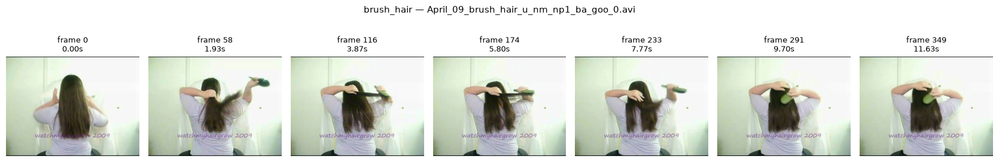

In [40]:
def show_temporal_strip(path: Path, num_frames: int = 8, title: str | None = None):
    frames = sample_video_frames(path, num_frames=num_frames)
    if not frames:
        print("Could not decode:", path)
        return

    fig, axes = plt.subplots(1, len(frames), figsize=(2.4 * len(frames), 3.2))
    if len(frames) == 1:
        axes = [axes]

    for ax, item in zip(axes, frames):
        ax.imshow(item["rgb"])
        ts = item["timestamp_sec"]
        ts_text = f"{ts:.2f}s" if np.isfinite(ts) else "time n/a"
        ax.set_title(f"frame {item['frame_index']}\n{ts_text}", fontsize=9)
        ax.axis("off")

    fig.suptitle(title or f"{path.parent.name} — {path.name}", fontsize=11)
    plt.tight_layout()
    plt.show()


if sample_candidates:
    show_temporal_strip(Path(sample_candidates[0]), num_frames=8)

## 8. Sample multiple sequences from each downloaded class

This produces a small gallery of temporal strips. The random seed makes the selected examples reproducible. You can change `VIDEOS_PER_CLASS` to inspect more examples.


CLASS: brush_hair | examples: 2


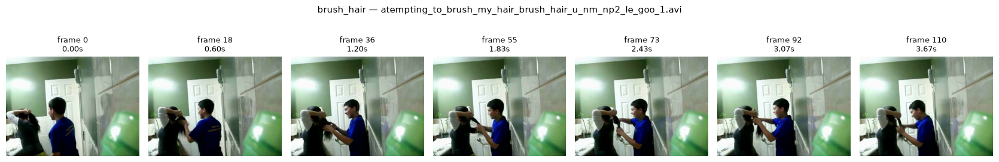

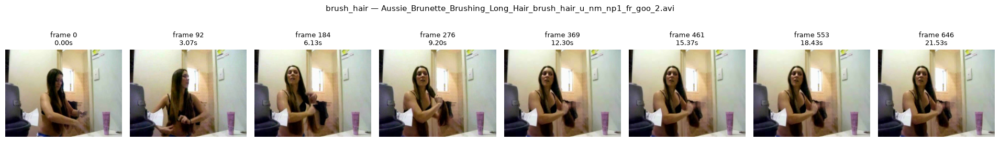


CLASS: cartwheel | examples: 2


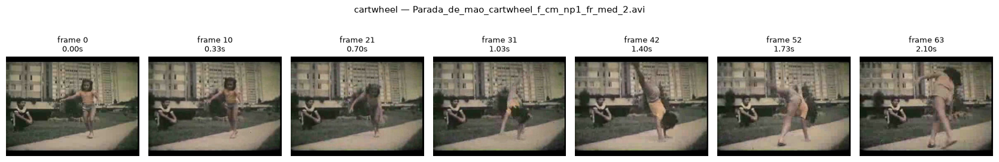

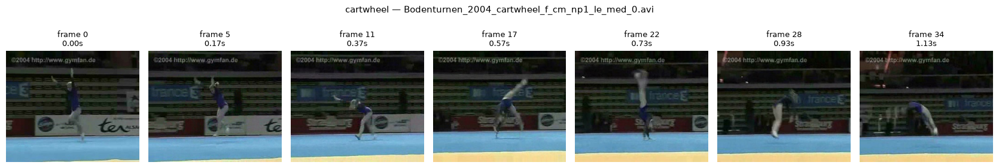


CLASS: catch | examples: 2


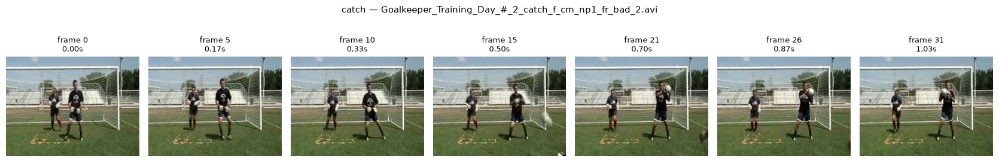

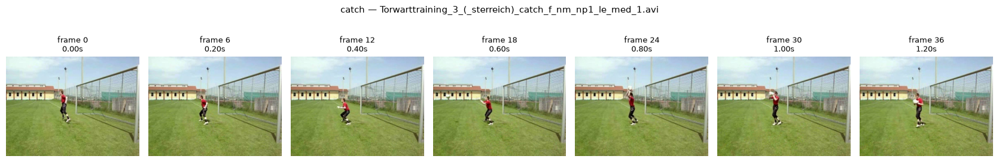


CLASS: chew | examples: 2


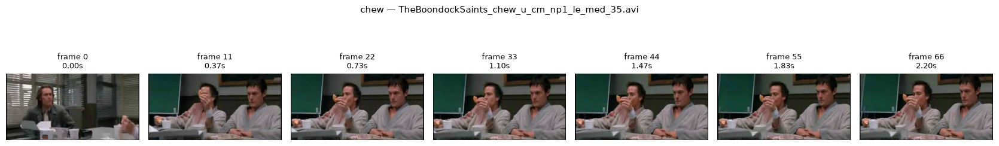

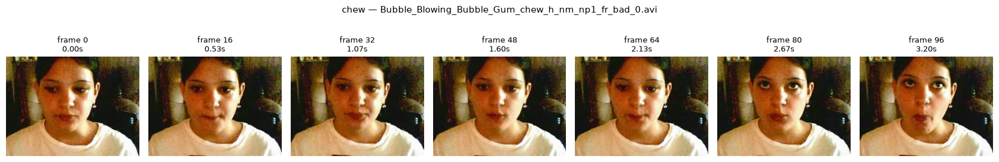


CLASS: clap | examples: 2


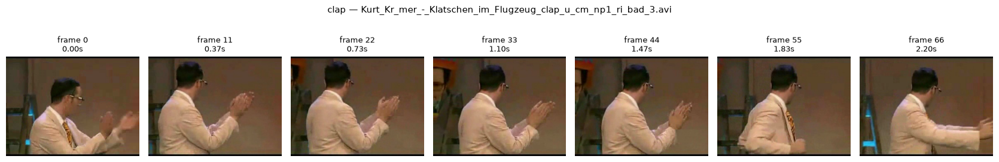

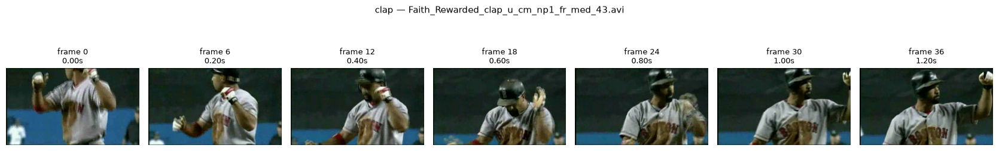


CLASS: climb | examples: 2


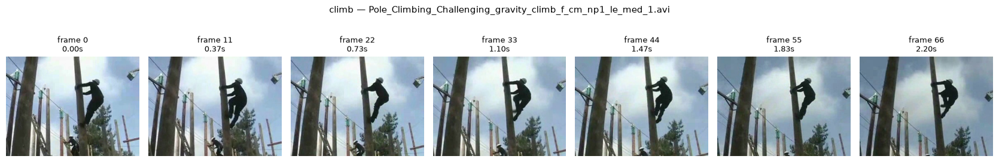

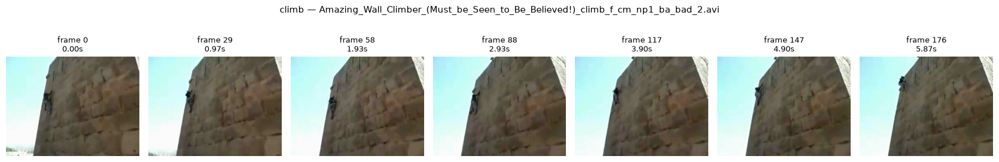


CLASS: climb_stairs | examples: 2


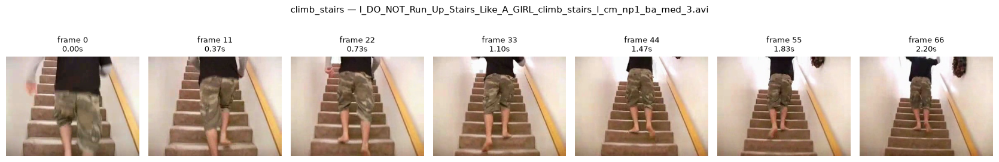

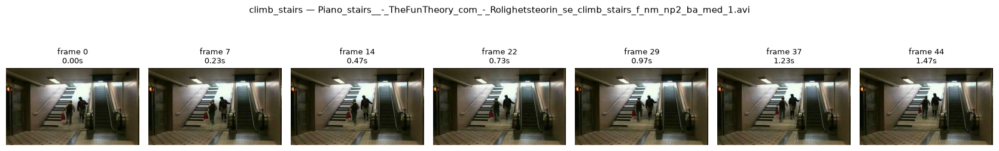


CLASS: dive | examples: 2


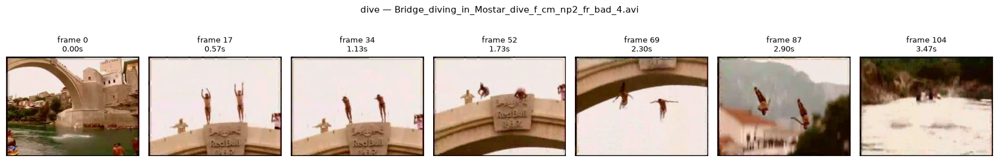

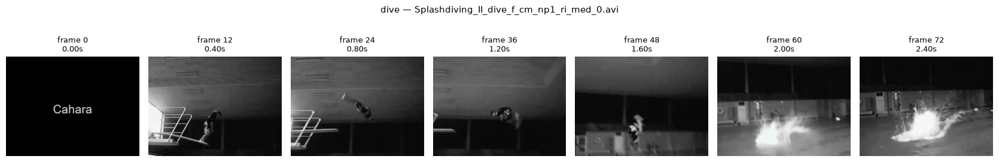


CLASS: draw_sword | examples: 2


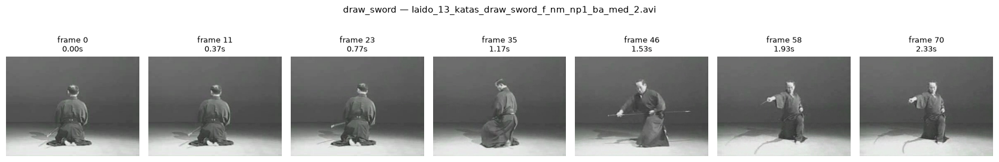

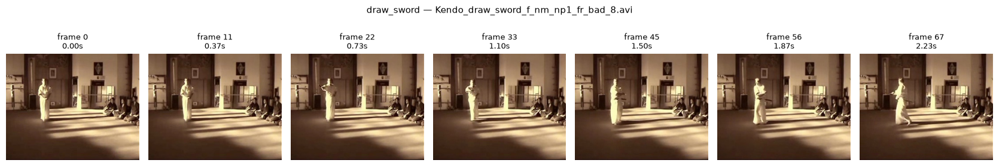

In [41]:
VIDEOS_PER_CLASS = 2
FRAMES_PER_VIDEO = 8

valid_inventory = inventory[inventory["video_path"].map(lambda p: str(p) in set(valid_stats["video_path"]))].copy()

for label, group in valid_inventory.groupby("label_from_folder"):
    examples = group.sample(
        n=min(VIDEOS_PER_CLASS, len(group)),
        random_state=SEED
    )
    print(f"\n{'='*90}\nCLASS: {label} | examples: {len(examples)}\n{'='*90}")
    for path in examples["video_path"]:
        show_temporal_strip(Path(path), num_frames=FRAMES_PER_VIDEO)

## 9. Sequence-level visual inspection worksheet

Use the frame strips above to record observations. The notebook deliberately does **not** automatically claim that an action is temporally identifiable: this requires visual inspection.

For each selected clip, consider:

| Question | What to look for |
|---|---|
| What changes across the sequence? | Body pose, hand/object position, object state, camera viewpoint, scene context |
| When does additional information become available? | At the start, during the action, near the end, or only after an outcome |
| Is a single frame ambiguous? | Could the same pose belong to another action? Is the object/person context insufficient? |
| Is temporal information unnecessary? | Does one frame already show a distinctive object, pose, or scene? |
| Is the sequence itself reliable? | Does the clip contain a clear action, or is it trimmed/occluded/edited? |

### Suggested action-level hypotheses to test

These are hypotheses to evaluate against the actual strips, not conclusions:

- **Potentially temporal:** `cartwheel`, `climb`, `climb_stairs`, `dive`. The action may be better characterized by a progression of body poses or movement through the scene than by a single static pose.
- **Potentially ambiguous in one frame:** `catch` may require observing an object approaching and then being received; `clap` may require observing hands moving together and separating.
- **Potentially less temporal / appearance-driven in some clips:** `brush_hair` or `chew` may sometimes be recognizable from a distinctive pose or context, although the action still unfolds over time.

The actual HMDB51 clips may contradict these hypotheses. Record the evidence from the sampled videos.

In [42]:
# Create a blank observation log that can be filled in during manual review.
observation_columns = [
    "video_path",
    "label",
    "what_changes_across_sequence",
    "when_information_becomes_available",
    "single_frame_ambiguous",
    "why_single_frame_is_ambiguous",
    "temporal_information_useful",
    "temporal_information_unnecessary",
    "notes",
]

observation_log = pd.DataFrame(columns=observation_columns)
display(observation_log)

# After filling rows, save with:
# observation_log.to_csv(DATA_ROOT / "sequence_observation_log.csv", index=False)

,video_path,label,what_changes_across_sequence,when_information_becomes_available,single_frame_ambiguous,why_single_frame_is_ambiguous,temporal_information_useful,temporal_information_unnecessary,notes


## 10. Compare early, middle, and late observations

This visualization helps answer *when* useful information becomes available. For a chosen clip, compare the first, middle, and final sampled frames side by side.

Do not confuse a later frame being more visually distinctive with proof that a temporal model has learned motion. This is an exploratory dataset analysis only.

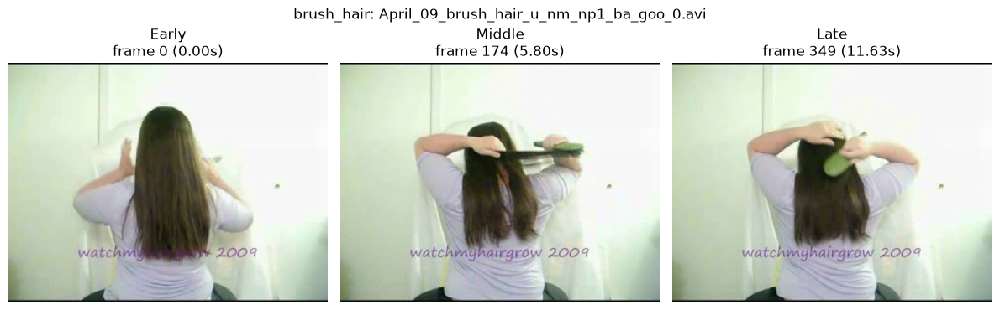

In [43]:
def compare_early_middle_late(path: Path):
    frames = sample_video_frames(path, num_frames=9)
    if len(frames) < 3:
        print("Not enough frames decoded.")
        return

    chosen = [frames[0], frames[len(frames)//2], frames[-1]]
    labels = ["Early", "Middle", "Late"]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, item, label in zip(axes, chosen, labels):
        ax.imshow(item["rgb"])
        ts = item["timestamp_sec"]
        time_label = f"{ts:.2f}s" if np.isfinite(ts) else "time n/a"
        ax.set_title(f"{label}\nframe {item['frame_index']} ({time_label})")
        ax.axis("off")

    fig.suptitle(f"{path.parent.name}: {path.name}")
    plt.tight_layout()
    plt.show()


# Change this to any video path printed in the gallery above.
if sample_candidates:
    compare_early_middle_late(Path(sample_candidates[0]))

## 11. Check temporal sampling and ordering explicitly

This cell verifies that the sampled frame indices and timestamps are strictly increasing for each inspected example. Duplicate indices can occur only if a clip is shorter than the requested number of frames; the sampler uses unique indices in that case.

This check is about the **sampling pipeline's ordering**, not the semantic correctness of the source video's timestamps.

In [44]:
def check_sample_order(path: Path, num_frames: int = 8) -> dict:
    frames = sample_video_frames(path, num_frames=num_frames)
    indices = [x["frame_index"] for x in frames]
    timestamps = [x["timestamp_sec"] for x in frames]
    index_ok = all(a < b for a, b in zip(indices, indices[1:]))

    finite_times = [t for t in timestamps if np.isfinite(t)]
    time_ok = all(a < b for a, b in zip(finite_times, finite_times[1:]))

    return {
        "video": path.name,
        "label": path.parent.name,
        "sampled_frames": len(frames),
        "indices": indices,
        "indices_strictly_increasing": index_ok,
        "timestamps_strictly_increasing": time_ok if len(finite_times) > 1 else None,
    }

order_checks = [
    check_sample_order(Path(p))
    for p in sample_candidates[:min(50, len(sample_candidates))]
]
order_df = pd.DataFrame(order_checks)

print("Videos checked:", len(order_df))
print("Index-order failures:",
      int((~order_df["indices_strictly_increasing"]).sum()))
print("Timestamp-order failures:",
      int((order_df["timestamps_strictly_increasing"] == False).sum()))
display(order_df.head(20))

Videos checked: 50
Index-order failures: 0
Timestamp-order failures: 0


,video,label,sampled_frames,indices,indices_strictly_increasing,timestamps_strictly_increasing
0,April_09_brush_hair_u_nm_np1_ba_goo_0.avi,brush_hair,7,"[0, 58, 116, 174, 233, 291, 349]",True,True
1,April_09_brush_hair_u_nm_np1_ba_goo_1.avi,brush_hair,7,"[0, 56, 112, 168, 225, 281, 337]",True,True
2,April_09_brush_hair_u_nm_np1_ba_goo_2.avi,brush_hair,7,"[0, 46, 92, 138, 184, 230, 276]",True,True
3,Aussie_Brunette_Brushing_Hair_II_brush_hair_u_...,brush_hair,7,"[0, 35, 70, 105, 140, 175, 210]",True,True
4,Aussie_Brunette_Brushing_Hair_II_brush_hair_u_...,brush_hair,7,"[0, 22, 45, 67, 90, 112, 135]",True,True
5,Aussie_Brunette_Brushing_Hair_II_brush_hair_u_...,brush_hair,7,"[0, 19, 38, 58, 77, 97, 116]",True,True
6,Aussie_Brunette_Brushing_Hair_II_brush_hair_u_...,brush_hair,7,"[0, 51, 102, 153, 204, 255, 306]",True,True
7,Aussie_Brunette_Brushing_Hair_II_brush_hair_u_...,brush_hair,7,"[0, 27, 54, 81, 108, 135, 162]",True,True
8,Aussie_Brunette_Brushing_Long_Hair_brush_hair_...,brush_hair,7,"[0, 62, 125, 187, 250, 312, 375]",True,True
9,Aussie_Brunette_Brushing_Long_Hair_brush_hair_...,brush_hair,8,"[0, 75, 150, 225, 301, 376, 451, 527]",True,True


## 12. Save reproducible dataset inspection outputs

Save:
- the local video inventory;
- video decoding/statistics results;
- metadata correspondence report;
- a JSON summary of the inspected dataset.

These files make the dataset section of the technical report reproducible.

In [45]:
OUTPUT_DIR = DATA_ROOT / "inspection"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

inventory.to_csv(OUTPUT_DIR / "local_video_inventory.csv", index=False)
video_stats.to_csv(OUTPUT_DIR / "video_decode_statistics.csv", index=False)
metadata_check.to_csv(OUTPUT_DIR / "metadata_local_correspondence.csv", index=False)
order_df.to_csv(OUTPUT_DIR / "sample_order_checks.csv", index=False)

summary = {
    "dataset": "HMDB51 mirror (Sina272/hmdb51-v2)",
    "local_dataset_root": str(DATA_ROOT),
    "local_avi_count": int(len(inventory)),
    "local_class_count": int(inventory["label_from_folder"].nunique()),
    "local_video_storage_mb": float(inventory["file_size_bytes"].sum() / (1024**2)),
    "metadata_rows": int(len(metadata)),
    "metadata_rows_with_local_video": int(metadata_check["exists_locally"].sum()),
    "videos_inspected": int(len(video_stats)),
    "videos_opened": int(video_stats["opened"].sum()),
    "videos_with_decoded_frames": int((video_stats["decoded_frames"] > 0).sum()),
    "videos_with_frame_count_match": int(video_stats["decode_complete"].sum()),
    "classes": sorted(inventory["label_from_folder"].unique().tolist()),
    "random_seed": SEED,
}

with open(OUTPUT_DIR / "dataset_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved inspection outputs to:", OUTPUT_DIR)
print(json.dumps(summary, indent=2))

Saved inspection outputs to: /Users/vanshikaarora/Desktop/Tracking/data/hmdb51/inspection
{
  "dataset": "HMDB51 mirror (Sina272/hmdb51-v2)",
  "local_dataset_root": "/Users/vanshikaarora/Desktop/Tracking/data/hmdb51",
  "local_avi_count": 950,
  "local_class_count": 9,
  "local_video_storage_mb": 325.05419921875,
  "metadata_rows": 6766,
  "metadata_rows_with_local_video": 950,
  "videos_inspected": 950,
  "videos_opened": 950,
  "videos_with_decoded_frames": 950,
  "videos_with_frame_count_match": 4,
  "classes": [
    "brush_hair",
    "cartwheel",
    "catch",
    "chew",
    "clap",
    "climb",
    "climb_stairs",
    "dive",
    "draw_sword"
  ],
  "random_seed": 42
}


## 13. Report-ready interpretation template

Use the actual values from the preceding cells and the manually completed observation log. Avoid claiming that temporal information helps simply because the data are videos; the later model experiments must test that claim.

### Dataset and sequence integrity
- Dataset source: HMDB51 mirror (`Sina272/hmdb51-v2`).
- Local subset: **[insert actual AVI count]** videos across **[insert class count]** classes.
- Downloaded video storage: **[insert measured MB]**.
- Metadata correspondence: **[insert matched/missing counts]**.
- Decoder integrity: **[insert number opened, decoded, and frame-count discrepancies]**.
- Sampling: **[insert frames per video]** approximately uniformly spaced frames, retained in ascending frame-index order.

### Temporal observations
- **What changes:** [describe body pose, object position, scene, camera, and action progression observed in the strips].
- **When information appears:** [describe whether the discriminative evidence appears early, midway, or late].
- **Single-frame ambiguity:** [give specific video/class examples and explain why a still frame is ambiguous].
- **Temporal information may be unnecessary:** [give examples where a single frame provides enough visual context].

### Limitations
- This is a partial download, not the full 51-class dataset.
- The local class distribution is determined by which files completed downloading.
- A frame strip samples only a small number of frames and may miss brief events.
- Metadata correspondence and successful decoding should be checked before model training.
- Visual inspection provides hypotheses; the controlled model experiments are needed to test whether a temporal model uses sequence information.

### Suggested evidence to include in the report
1. A class-count bar chart.
2. A table of video FPS, duration, resolution, and decoded-frame statistics.
3. Three to six temporal frame strips from different classes.
4. At least one example where a single frame is ambiguous but the sequence clarifies the action.
5. At least one example where a single frame appears sufficient.

## 14. Next stage

After this notebook runs successfully, the next notebook should:

1. Define video-level train/validation/test splits.
2. Sample a fixed number of frames per video (for example, 8).
3. Extract frozen DINOv2 frame embeddings.
4. Cache embeddings to disk.
5. Train and compare a single-frame baseline, mean-pooling baseline, and GRU temporal model using exactly the same video splits.

**Do not create the train/test split at the frame level.** Every frame from one video must remain in the same split.

### Initial Observation: Limitations of Single-Frame Understanding

During manual inspection of the HMDB51 video sequences, I observed that an individual frame does not always provide sufficient information to understand the complete action being performed.

A single frame captures the subject's appearance and pose at a particular moment, but it may not reveal the preceding movement, the ongoing action, or its eventual outcome.

Observing multiple frames in chronological order provides additional context by revealing changes in body posture, object positions, interactions, and movement progression.

This suggests that temporal information may be important for distinguishing actions that appear visually similar in individual frames but differ in how they evolve over time.
